# 03: What enemy utility hurts us most?

**Question:** which of the opponents' nades (and where they land) show up in the rounds we lose?

Same data as notebook 02: the 64 demos that match FACEIT's scoreboard, gun rounds only.

**The trap:** in rounds we lose, the enemy throws *more* nades just because those rounds last longer (retakes, post-plant, chasing the last guy).
So, same rule as notebook 02: **only nades and damage from before the first kill of the round** count.
That's the set-up utility, the stuff that's meant to win the round before anyone has died.

> 📝 = my own take.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P = ROOT / "data" / "processed"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

quality = pd.read_parquet(P / "demo_quality.parquet")
OK = set(quality.loc[quality["ok"], "match_id"])

rf = pd.read_parquet(P / "round_features.parquet")
gun = rf[rf["match_id"].isin(OK) & ~rf["is_pistol"]].copy()
kills = pd.read_parquet(P / "kills.parquet").query("match_id in @OK and not after_round_end")
nades = pd.read_parquet(P / "grenades.parquet").query("match_id in @OK and not after_round_end")
dmg = pd.read_parquet(P / "damage.parquet").query("match_id in @OK and not after_round_end")
pos = pd.read_parquet(P / "positions.parquet", columns=["match_id", "X", "Y", "Z", "place"]).query("match_id in @OK and place != ''")

KEY = ["match_id", "round"]
MAPS = {m: m.replace("de_", "").title() for m in gun["map"].unique()}
maps = gun[["match_id", "map"]].drop_duplicates()

# "before the first kill" = before the opening kill's tick
open_tick = kills[kills["is_opening"]].groupby(KEY)["tick"].min().rename("open_tick")
for t in (nades, dmg):
    t["pre"] = t["tick"] < t.join(open_tick, on=KEY)["open_tick"].fillna(np.inf)

plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
WIN, LOSS, NEUTRAL, US, THEM = "#2a9d8f", "#e76f51", "#6c757d", "#264653", "#e9c46a"
TYPE_COL = {"smoke": "#6c757d", "flash": "#e9c46a", "he": "#264653", "molotov": "#e76f51"}

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

print(f"{gun['match_id'].nunique()} demos, {len(gun)} gun rounds")

64 demos, 1288 gun rounds


In [2]:
# name each landing spot with the callout of the nearest spot a player has ever stood on that map
nades = nades.merge(maps, on="match_id")
nades["land_place"] = ""
for m, sub in nades.groupby("map"):
    p = pos[pos["match_id"].isin(maps.loc[maps["map"] == m, "match_id"])]
    p = p.sample(min(len(p), 200_000), random_state=0)
    _, idx = cKDTree(p[["X", "Y", "Z"]].values).query(sub[["land_X", "land_Y", "land_Z"]].values)
    nades.loc[sub.index, "land_place"] = p["place"].values[idx]

nades = nades.merge(gun[KEY + ["my_side", "my_team_won"]], on=KEY)
UTIL = ["smoke", "flash", "he", "molotov"]
enemy_pre = nades[~nades["thrower_is_my_team"] & nades["type"].isin(UTIL) & nades["pre"]]
print(f"enemy nades per gun round: {(~nades['thrower_is_my_team']).sum() / len(gun):.1f} in total, "
      f"{len(enemy_pre) / len(gun):.1f} before the first kill")

enemy nades per gun round: 7.4 in total, 3.4 before the first kill


## 1. What does their utility actually do to us?

In [3]:
UTIL_DMG = ["inferno", "hegrenade"]
pre_dmg = dmg[dmg["pre"] & dmg["weapon"].isin(UTIL_DMG)]
r = gun.set_index(KEY)
r["nade_dmg_taken"] = pre_dmg[~pre_dmg["attacker_is_my_team"] & pre_dmg["victim_is_my_team"]].groupby(KEY)["dmg_real"].sum()
r["nade_dmg_dealt"] = pre_dmg[pre_dmg["attacker_is_my_team"] & ~pre_dmg["victim_is_my_team"]].groupby(KEY)["dmg_real"].sum()
r[["nade_dmg_taken", "nade_dmg_dealt"]] = r[["nade_dmg_taken", "nade_dmg_dealt"]].fillna(0)

flashes = nades[(nades["type"] == "flash") & nades["pre"]]
our_deaths, their_deaths = kills[kills["victim_is_my_team"]], kills[~kills["victim_is_my_team"]]
pd.DataFrame({
    "us": [r.loc[r["my_side"] == "T", "nade_dmg_taken"].mean(), r.loc[r["my_side"] == "CT", "nade_dmg_taken"].mean(),
           flashes.loc[~flashes["thrower_is_my_team"], "enemies_flashed"].mean(),
           our_deaths["assistedflash"].mean(), our_deaths["thrusmoke"].mean()],
    "opponents": [r.loc[r["my_side"] == "CT", "nade_dmg_dealt"].mean(), r.loc[r["my_side"] == "T", "nade_dmg_dealt"].mean(),
                  flashes.loc[flashes["thrower_is_my_team"], "enemies_flashed"].mean(),
                  their_deaths["assistedflash"].mean(), their_deaths["thrusmoke"].mean()],
}, index=["HE/molly damage taken before first kill, as T", "... as CT",
          "players blinded per flash thrown at them", "deaths with a flash assist", "deaths through a smoke"]).round(3)

,us,opponents
"HE/molly damage taken before first kill, as T",10.275,11.744
... as CT,4.653,3.333
players blinded per flash thrown at them,1.036,0.999
deaths with a flash assist,0.024,0.019
deaths through a smoke,0.054,0.054


Read the "us" column as *what happens to us*, and "opponents" as *the same thing happening to them*.

**Pretty even.** Before the first kill we take about as much nade damage as we deal, and our flashes blind about as many people as theirs.
Deaths straight off a flash or through a smoke are rare for everyone (2–5%).
So it's not that their utility does way more *damage*. If it hurts, it's by **where it lands and what it lets them do**.

## 2. Dead end: chip damage before the first fight

In [4]:
r["dmg_bucket"] = pd.cut(r["nade_dmg_taken"], [-1, 0, 40, 1000], labels=["0", "1–40", "40+"])
show = lambda d: d.groupby(["my_side", "dmg_bucket"], observed=True).agg(
    rounds=("my_team_won", "size"), we_won_first_duel=("opening_ours", "mean"), round_win=("my_team_won", "mean")).round(2)
all_rounds = show(r)
both_full = show(r[(r["my_team_buy"] == "full") & (r["enemy_buy"] == "full")])
pd.concat({"all gun rounds": all_rounds, "both teams full buy": both_full}, axis=1)

all gun rounds                              \
                           rounds we_won_first_duel round_win   
my_side dmg_bucket                                              
CT      0                     555              0.57      0.55   
        1–40                   62              0.47      0.47   
        40+                    32              0.25      0.38   
T       0                     466              0.52      0.52   
        1–40                   96              0.44      0.43   
        40+                    77              0.43      0.42   

                   both teams full buy                              
                                rounds we_won_first_duel round_win  
my_side dmg_bucket                                                  
CT      0                          229              0.61      0.59  
        1–40                        27              0.56      0.63  
        40+                         13              0.38      0.46  
T       0                          202              0.50      0.48  
        1–40                        45              0.51      0.40  
        40+                         39              0.46      0.49

At first this looks huge: on CT, taking **40+** nade damage before the first fight drops our first-duel win rate and round win a lot.
But when both teams are on a **full buy** the effect mostly disappears (on T it's flat).
That's the economy talking: rich teams throw more HE and molly *and* win more, for reasons that have nothing to do with the chip damage.
So chip damage on its own isn't the answer.

## 3. Which enemy nade spots go with losing?

For each map, side, nade type and landing callout: how often do we win rounds where the enemy threw that nade there **before the first kill**, compared with rounds where they didn't?

To keep the economy out of it, the difference is worked out **within each buy matchup** (our buy × their buy) and then averaged.
The 95% interval comes from a bootstrap that resamples whole matches.

In [5]:
gun["stratum"] = gun["my_team_buy"] + "|" + gun["enemy_buy"]
rng = np.random.default_rng(0)

def adjusted_diff(tab):
    # tab: per (stratum, with) -> rounds, wins. Weighted by rounds 'with' the nade.
    t = tab.unstack("with", fill_value=0)
    t = t[(t[("rounds", True)] > 0) & (t[("rounds", False)] > 0)]
    if t.empty:
        return np.nan
    diff = t[("wins", True)] / t[("rounds", True)] - t[("wins", False)] / t[("rounds", False)]
    return np.average(diff, weights=t[("rounds", True)])

rows = []
for (m, side), rounds in gun[gun["map"].isin(["de_mirage", "de_inferno", "de_dust2"])].groupby(["map", "my_side"]):
    rounds = rounds[KEY + ["stratum", "my_team_won"]]
    matches = rounds["match_id"].unique()
    spots = enemy_pre[(enemy_pre["map"] == m) & (enemy_pre["my_side"] == side)][["type", "land_place"] + KEY].drop_duplicates()
    for (typ, place), s in spots.groupby(["type", "land_place"]):
        if len(s) < 20:
            continue
        rr = rounds.assign(with_=rounds.set_index(KEY).index.isin(s.set_index(KEY).index)).rename(columns={"with_": "with"})
        per_match = rr.groupby(["match_id", "stratum", "with"])["my_team_won"].agg(rounds="size", wins="sum")
        est = adjusted_diff(per_match.groupby(["stratum", "with"]).sum())
        boot = []
        for _ in range(400):
            pick = pd.Series(rng.choice(matches, len(matches))).value_counts()
            w = per_match.mul(per_match.index.get_level_values("match_id").map(pick).fillna(0).values, axis=0)
            boot.append(adjusted_diff(w.groupby(["stratum", "with"]).sum()))
        lo, hi = np.nanpercentile(boot, [2.5, 97.5])
        rows.append(dict(map=MAPS[m], our_side=side, nade=typ, lands_at=place, rounds=int(rr["with"].sum()),
                         share_of_rounds=rr["with"].mean(), win_with=rr.loc[rr["with"], "my_team_won"].mean(),
                         win_without=rr.loc[~rr["with"], "my_team_won"].mean(), adjusted_diff=est, ci_low=lo, ci_high=hi))

spots = pd.DataFrame(rows).sort_values("adjusted_diff").reset_index(drop=True)
print(f"{len(spots)} spot/nade combos tested; {((spots['ci_high'] < 0) | (spots['ci_low'] > 0)).sum()} have an interval that excludes 0")
spots.head(10).round(2)

50 spot/nade combos tested; 4 have an interval that excludes 0


,map,our_side,nade,lands_at,rounds,share_of_rounds,win_with,win_without,adjusted_diff,ci_low,ci_high
0,Inferno,T,smoke,Middle,90,0.59,0.44,0.63,-0.22,-0.32,-0.06
1,Dust2,T,flash,LongA,36,0.35,0.36,0.63,-0.20,-0.36,-0.04
2,Mirage,CT,molotov,Middle,29,0.09,0.38,0.58,-0.17,-0.36,0.01
3,Dust2,T,smoke,LongDoors,20,0.19,0.35,0.58,-0.16,-0.51,0.07
4,Mirage,CT,smoke,SnipersNest,152,0.47,0.46,0.65,-0.14,-0.28,-0.00
5,Mirage,T,he,TopofMid,23,0.08,0.35,0.51,-0.14,-0.37,0.05
6,Mirage,T,flash,Catwalk,44,0.15,0.36,0.53,-0.11,-0.25,0.02
7,Inferno,T,flash,Banana,60,0.39,0.48,0.55,-0.10,-0.26,0.12
8,Dust2,T,he,LongDoors,23,0.22,0.39,0.57,-0.10,-0.35,0.12
9,Mirage,T,smoke,PalaceInterior,112,0.38,0.41,0.56,-0.10,-0.25,0.03


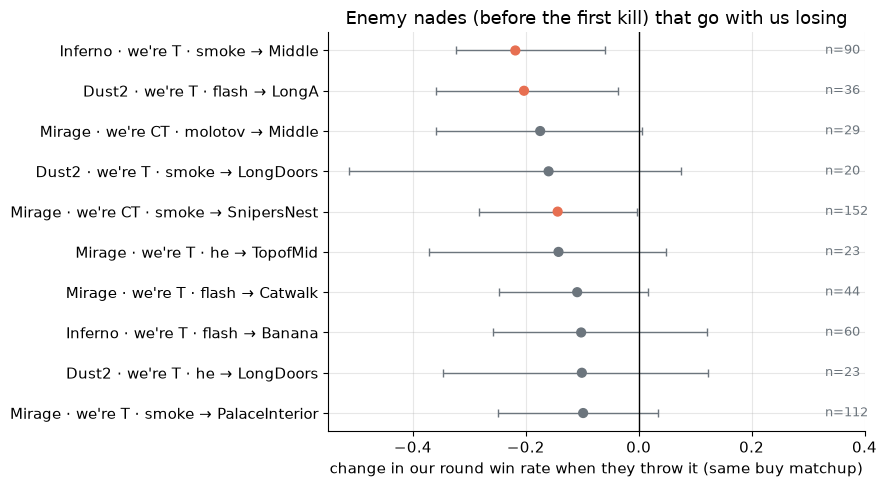

In [6]:
top = spots.head(10).iloc[::-1]
labels = top["map"] + " · we're " + top["our_side"] + " · " + top["nade"] + " → " + top["lands_at"]
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(top))
sig = top["ci_high"] < 0
ax.errorbar(top["adjusted_diff"], y, xerr=[top["adjusted_diff"] - top["ci_low"], top["ci_high"] - top["adjusted_diff"]],
            fmt="none", ecolor=NEUTRAL, capsize=3, lw=1)
ax.scatter(top["adjusted_diff"], y, color=np.where(sig, LOSS, NEUTRAL), zorder=3, s=40)
for yi, n in zip(y, top["rounds"]):
    ax.text(0.33, yi, f"n={n}", va="center", fontsize=9, color=NEUTRAL)
ax.axvline(0, color="black", lw=1)
ax.set_yticks(y, labels)
ax.set_xlim(-0.55, 0.4)
ax.set_xlabel("change in our round win rate when they throw it (same buy matchup)")
ax.set_title("Enemy nades (before the first kill) that go with us losing")
save("03_enemy_nade_spots")

**Careful reading this.** I tested 50 combos, so by pure luck about 2–3 of them would "look significant" anyway.
4 have an interval that clears zero, so one or two of those might just be noise. The ones worth believing are the ones that are **common and make sense**:

- **Mirage, we're CT, they smoke Window** (152 rounds, almost half): our win rate drops from ~65% to ~46% (adjusted −14 points, interval only just clears zero, but it's by far the biggest sample).
- **Inferno, we're T, they smoke Mid** (90 rounds): ~63% → ~44%.
- **Dust2, we're T, they flash Long** (36 rounds): ~63% → ~36%.

Also: a team that throws the standard smokes is probably just a *better team*. The buy matchup doesn't capture that, so these show where their utility lines up with our losses, not proof it causes them.

> 📝 **Inferno T, when they smoke mid:** we tend to wait, I think. Mostly everything comes to a halt, I feel.
>
> 📝 **Dust2 T, Long:** when we go Long it's usually as a team. We rain flashes over and try to force it.

In [7]:
# checking "everything comes to a halt": Inferno T, rounds where the CTs smoke Middle before the first kill
sm = enemy_pre[(enemy_pre["map"] == "de_inferno") & (enemy_pre["my_side"] == "T") &
               (enemy_pre["type"] == "smoke") & (enemy_pre["land_place"] == "Middle")][KEY].drop_duplicates()
inf_t = gun[(gun["map"] == "de_inferno") & (gun["my_side"] == "T")].copy()
inf_t["they_smoked_mid"] = inf_t.set_index(KEY).index.isin(sm.set_index(KEY).index)
inf_t.groupby("they_smoked_mid").agg(
    rounds=("round", "size"), first_kill_at_s=("opening_time_s", "median"), we_won_first_duel=("opening_ours", "mean"),
    planted=("bomb_planted", "mean"), round_win=("my_team_won", "mean")).round(2)

,rounds,first_kill_at_s,we_won_first_duel,planted,round_win
they_smoked_mid,,,,,
False,63,13.81,0.59,0.70,0.63
True,90,22.17,0.50,0.54,0.44


**The halt is real.** When the CTs smoke mid on Inferno, the first kill comes about **8 seconds later** (median ~0:22 instead of ~0:14),
we plant less (54% vs 70%) and win less (44% vs 63%). Waiting doesn't buy us anything, it just gives the CTs time.
Same lesson as notebook 02, section 8: waiting on its own isn't a plan.

Dust2 Long is still open: "rain flashes and force it" is our plan, but the rounds that hurt are the ones where *their* flash lands on Long first. Whether that's the CTs pushing out to take Long, or flashing our walk-in, needs a look at the demos (only 36 rounds).

## 4. On the map: Mirage

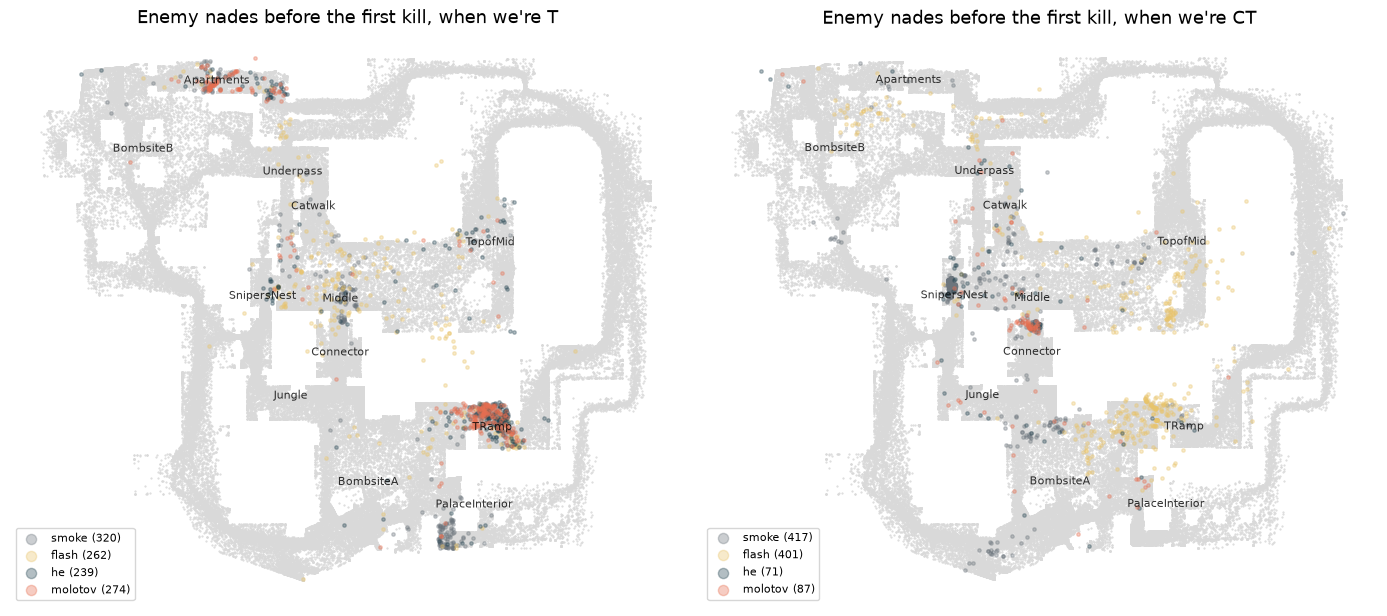

In [8]:
mir_ids = maps.loc[maps["map"] == "de_mirage", "match_id"]
bg = pos[pos["match_id"].isin(mir_ids)].sample(120_000, random_state=1)
labels_xy = bg.groupby("place")[["X", "Y"]].median()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, side in zip(axes, ["T", "CT"]):
    ax.scatter(bg["X"], bg["Y"], s=0.3, color="#d9d9d9", rasterized=True)
    e = enemy_pre[(enemy_pre["map"] == "de_mirage") & (enemy_pre["my_side"] == side)]
    for typ, col in TYPE_COL.items():
        d = e[e["type"] == typ]
        ax.scatter(d["land_X"], d["land_Y"], s=6, color=col, alpha=0.35, label=f"{typ} ({len(d)})")
    for place in ["TopofMid", "Middle", "SnipersNest", "PalaceInterior", "TRamp", "Apartments", "BombsiteA", "BombsiteB", "Catwalk", "Connector", "Jungle", "Underpass"]:
        if place in labels_xy.index:
            ax.text(*labels_xy.loc[place], place, fontsize=8, ha="center", color="black", alpha=0.8)
    ax.set_title(f"Enemy nades before the first kill, when we're {side}")
    ax.set_aspect("equal"); ax.axis("off")
    ax.legend(loc="lower left", fontsize=8, markerscale=3)
save("03_mirage_enemy_nades")

Where the opponents' set-up utility lands on Mirage. The grey background is every spot a player stood on (I don't have a radar image, so this *is* the map).
When we're T it's the CT defaults: Palace, A ramp, Apartments, Top of Mid. When we're CT, it's their mid take: **Window, Top of Mid, Connector**.

## 5. Mirage CT: what happens when they smoke Window?

In [9]:
ws = enemy_pre[(enemy_pre["map"] == "de_mirage") & (enemy_pre["my_side"] == "CT") &
               (enemy_pre["type"] == "smoke") & (enemy_pre["land_place"] == "SnipersNest")][KEY].drop_duplicates()
mc = gun[(gun["map"] == "de_mirage") & (gun["my_side"] == "CT")].copy()
mc["they_smoked_window"] = mc.set_index(KEY).index.isin(ws.set_index(KEY).index)
display(mc.groupby("they_smoked_window").agg(
    rounds=("round", "size"), round_win=("my_team_won", "mean"), we_won_first_duel=("opening_ours", "mean"),
    first_kill_at_s=("opening_time_s", "median")).round(2))

lost_first = mc[~mc["opening_ours"]]
display(lost_first.groupby("they_smoked_window")["opening_place"].value_counts(normalize=True)
        .groupby(level=0).head(4).round(2).rename("share of our first deaths"))

first_ct = kills[kills["is_opening"] & kills["victim_is_my_team"]].merge(mc[KEY + ["they_smoked_window"]], on=KEY)
mid_deaths = first_ct[first_ct["they_smoked_window"] & (first_ct["victim_last_place_name"].isin(["Middle", "TopofMid", "SnipersNest"]))]
mid_deaths["victim_name"].value_counts().head(5).rename("who died first in mid after a Window smoke")

,rounds,round_win,we_won_first_duel,first_kill_at_s
they_smoked_window,,,,
False,172,0.65,0.59,12.64
True,152,0.46,0.50,15.60


they_smoked_window  opening_place 
False               BombsiteA         0.31
                    SnipersNest       0.18
                    Middle            0.08
                    PalaceInterior    0.07
True                Middle            0.25
                    BombsiteA         0.14
                    PalaceInterior    0.12
                    Underpass         0.09
Name: share of our first deaths, dtype: float64

victim_name
Inbail      9
MlgSly      5
Toe_bias    3
Pen_Trix    1
iZeRo3      1
Name: who died first in mid after a Window smoke, dtype: int64

When they smoke Window, our CT side gets **pushed out of mid**: our first death moves to **Middle** (a quarter of our first deaths, vs 8% when they don't),
and we win the first duel less (50% vs 59%). The one who dies first in mid after a Window smoke is mostly **Inbail** (9 times), then me (5).

It's the mirror of notebook 02: there, **our** Window smoke on T barely helped us. Here, **their** Window smoke on CT hurts us a lot.
The difference is probably what comes *after* the smoke: they use it to take mid, we just smoke it and peek.

> 📝 **My take:** on Mirage CT, when they smoke mid we try to take note of Connector and Short. But Inbail is usually quite an impatient player and likes to duel mid.

## Summary: answer to question 2

1. **Their utility doesn't do more damage than ours.** Before the first kill, nade damage, flashes and flash-assisted kills are about even.
2. **Dead end:** chip damage before the first fight *looked* like it mattered, but it's mostly the economy.
3. **Where it lands matters more.** The clearest one: on **Mirage CT, when they smoke Window** (almost half the rounds) our win rate drops from ~65% to ~46%, and our first death moves into mid.
4. Other candidates: **Inferno T** when they smoke Mid, **Dust2 T** when they flash Long. These have smaller samples and are partly "better teams use more standard utility".

**For the experiment:** a Mirage CT plan for when Window gets smoked (who falls back, who holds the mid push), and on T, using our own Window smoke to actually *take* mid instead of just peeking it.

> 📝 **My take, in my own words:** (3–5 bullets)